<a href="https://colab.research.google.com/github/HinnaNayab/DeepLearning/blob/Applied-AI/Tutorial_7_Transfer_Learning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import datasets, transforms, models
from torch.utils.data import DataLoader

In [2]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [3]:
#loading and pre-processing the CIFAR-10 dataset
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.4914, 0.4822, 0.4465), (0.2023, 0.1994, 0.2010))
]) #what is happening here??

train_dataset = datasets.CIFAR10(root="./data", train=True, download=True, transform=transform)
test_dataset = datasets.CIFAR10(root="./data", train=False, download=True, transform=transform)

train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True, num_workers=2)
test_loader = DataLoader(test_dataset, batch_size=64, shuffle=False, num_workers=2)

100%|██████████| 170M/170M [18:08<00:00, 157kB/s]


In [10]:
#model training and evaluation
def train_and_evaluate(model, train_loader, test_loader, optimizer, epochs=5, name="Model"):
    criterion = nn.CrossEntropyLoss()
    model.to(device)

    for epoch in range(epochs):
        model.train()
        running_loss = 0.0
        for images, labels in train_loader:
            images, labels = images.to(device), labels.to(device)
            optimizer.zero_grad()
            outputs = model(images)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()
            running_loss += loss.item()
        print(f"[{name}] Epoch {epoch+1}/{epochs} - Loss: {running_loss/len(train_loader):.4f}")
        model.eval()
    correct, total = 0, 0
    with torch.no_grad():
        for images, labels in test_loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            _, predicted = torch.max(outputs, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()

    acc = 100.0 * correct / total
    print(f"[{name}] Test Accuracy: {acc:.2f}%\n")
    return acc

In [9]:
#Now, feature extraction using pre-trained VGG-16
#Transfer learning has oevrarching two essential things:
#1. Feature Extraction and 2. Fine-Tuning
vgg16_fe = models.vgg16(weights="DEFAULT")

# Freeze all convolutional backbone layers
for param in vgg16_fe.features.parameters():
    param.requires_grad = False

# Replace classifier head for 10 CIFAR-10 classes
vgg16_fe.classifier = nn.Sequential(
    nn.Linear(512 * 7 * 7, 512),
    nn.ReLU(),
    nn.Dropout(0.3),
    nn.Linear(512, 10)
)

optimizer_vgg_fe = optim.Adam(vgg16_fe.classifier.parameters(), lr=1e-3)
acc_vgg_fe = train_and_evaluate(vgg16_fe, train_loader, test_loader, optimizer_vgg_fe, epochs=5, name="VGG16 Feature Extraction")



Downloading: "https://download.pytorch.org/models/vgg16-397923af.pth" to /root/.cache/torch/hub/checkpoints/vgg16-397923af.pth


100%|██████████| 528M/528M [00:07<00:00, 73.8MB/s]


[VGG16 Feature Extraction] Epoch 1/5 - Loss: 1.2866
[VGG16 Feature Extraction] Epoch 2/5 - Loss: 1.1219
[VGG16 Feature Extraction] Epoch 3/5 - Loss: 1.0810
[VGG16 Feature Extraction] Epoch 4/5 - Loss: 1.0577
[VGG16 Feature Extraction] Epoch 5/5 - Loss: 1.0340
[VGG16 Feature Extraction] Test Accuracy: 65.08%



In [11]:
#Now, Fine-tuning using Pre-trained ResNet-50

# ---------------------------------------------------------
# Step 3B: Fine-Tuning using Pretrained ResNet50
# ---------------------------------------------------------
resnet50_ft = models.resnet50(weights="DEFAULT")

# Initially freeze all layers
for param in resnet50_ft.parameters():
    param.requires_grad = False

# Unfreeze the last residual block (layer4) for fine-tuning
for param in resnet50_ft.layer4.parameters():
    param.requires_grad = True

# Replace final fully connected layer for 10 classes
resnet50_ft.fc = nn.Sequential(
    nn.Linear(resnet50_ft.fc.in_features, 512),
    nn.ReLU(),
    nn.Linear(512, 10)
)

# Train only unfrozen parameters with a low learning rate (1e-4 / 1e-5)
optimizer_resnet_ft = optim.Adam(filter(lambda p: p.requires_grad, resnet50_ft.parameters()), lr=1e-4)
acc_resnet_ft = train_and_evaluate(resnet50_ft, train_loader, test_loader, optimizer_resnet_ft, epochs=5, name="ResNet50 Fine-Tuning")

# Step 4 & 5: Compare Results
print("=== FINAL COMPARISON ===")
print(f"VGG16 Feature Extraction Accuracy: {acc_vgg_fe:.2f}%")
print(f"ResNet50 Fine-Tuning Accuracy: {acc_resnet_ft:.2f}%")

Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 206MB/s]


[ResNet50 Fine-Tuning] Epoch 1/5 - Loss: 1.4294
[ResNet50 Fine-Tuning] Epoch 2/5 - Loss: 0.8984
[ResNet50 Fine-Tuning] Epoch 3/5 - Loss: 0.6925
[ResNet50 Fine-Tuning] Epoch 4/5 - Loss: 0.5528
[ResNet50 Fine-Tuning] Epoch 5/5 - Loss: 0.4444
[ResNet50 Fine-Tuning] Test Accuracy: 72.68%

=== FINAL COMPARISON ===
VGG16 Feature Extraction Accuracy: 65.08%
ResNet50 Fine-Tuning Accuracy: 72.68%


In [12]:
#Solving for tasks assigned 3 and 4
#3: Do feature extraction with Resnet50 compare the results with custom model and VGG16.
#4: Do finetuning with VGG 16 and feature extraction with Resnet50

#3: Feature Extraction with ResNet50 (All backbone frozen, only fc trained)
resnet50_fe = models.resnet50(weights="DEFAULT")
for param in resnet50_fe.parameters():
    param.requires_grad = False
resnet50_fe.fc = nn.Sequential(nn.Linear(resnet50_fe.fc.in_features, 512), nn.ReLU(), nn.Linear(512, 10))

opt_res_fe = optim.Adam(resnet50_fe.fc.parameters(), lr=1e-3)
acc_res_fe = train_and_evaluate(resnet50_fe, train_loader, test_loader, opt_res_fe, epochs=5, name="ResNet50 Feature Extraction")

# 4. Fine-Tuning with VGG16 (Unfreeze last conv block features[24:] + classifier)
vgg16_ft = models.vgg16(weights="DEFAULT")
for param in vgg16_ft.features.parameters():
    param.requires_grad = False
for param in vgg16_ft.features[24:].parameters():
    param.requires_grad = True

vgg16_ft.classifier = nn.Sequential(nn.Linear(512 * 7 * 7, 512), nn.ReLU(), nn.Linear(512, 10))
opt_vgg_ft = optim.Adam(filter(lambda p: p.requires_grad, vgg16_ft.parameters()), lr=1e-4)
acc_vgg_ft = train_and_evaluate(vgg16_ft, train_loader, test_loader, opt_vgg_ft, epochs=5, name="VGG16 Fine-Tuning")

print(f"ResNet50 FE: {acc_res_fe:.2f}% | VGG16 FT: {acc_vgg_ft:.2f}%")

[ResNet50 Feature Extraction] Epoch 1/5 - Loss: 1.7171
[ResNet50 Feature Extraction] Epoch 2/5 - Loss: 1.5547
[ResNet50 Feature Extraction] Epoch 3/5 - Loss: 1.4961
[ResNet50 Feature Extraction] Epoch 4/5 - Loss: 1.4546
[ResNet50 Feature Extraction] Epoch 5/5 - Loss: 1.4244
[ResNet50 Feature Extraction] Test Accuracy: 49.17%

[VGG16 Fine-Tuning] Epoch 1/5 - Loss: 0.7677
[VGG16 Fine-Tuning] Epoch 2/5 - Loss: 0.4928
[VGG16 Fine-Tuning] Epoch 3/5 - Loss: 0.3421
[VGG16 Fine-Tuning] Epoch 4/5 - Loss: 0.2216
[VGG16 Fine-Tuning] Epoch 5/5 - Loss: 0.1436
[VGG16 Fine-Tuning] Test Accuracy: 80.96%

ResNet50 FE: 49.17% | VGG16 FT: 80.96%


100%|██████████| 170M/170M [22:55<00:00, 124kB/s]


Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 211MB/s]


[Baseline] Epoch 01/8 | Train Acc: 50.2% | Val Acc: 66.1% | Val Loss: 1.0586
[Baseline] Epoch 02/8 | Train Acc: 75.8% | Val Acc: 70.6% | Val Loss: 0.9386
[Baseline] Epoch 03/8 | Train Acc: 86.7% | Val Acc: 69.8% | Val Loss: 1.0518
[Baseline] Epoch 04/8 | Train Acc: 91.6% | Val Acc: 68.5% | Val Loss: 1.1798
[Baseline] Epoch 05/8 | Train Acc: 94.1% | Val Acc: 70.5% | Val Loss: 1.1580
[Baseline] Epoch 06/8 | Train Acc: 94.9% | Val Acc: 69.7% | Val Loss: 1.2319
[Baseline] Epoch 07/8 | Train Acc: 95.8% | Val Acc: 70.0% | Val Loss: 1.1533
[Baseline] Epoch 08/8 | Train Acc: 96.4% | Val Acc: 68.9% | Val Loss: 1.2341
[Improved] Epoch 01/12 | Train Acc: 81.5% | Val Acc: 92.0% | Val Loss: 0.2467
[Improved] Epoch 02/12 | Train Acc: 93.1% | Val Acc: 92.7% | Val Loss: 0.2217
[Improved] Epoch 03/12 | Train Acc: 95.2% | Val Acc: 92.7% | Val Loss: 0.2193
[Improved] Epoch 04/12 | Train Acc: 96.8% | Val Acc: 93.2% | Val Loss: 0.2116
[Improved] Epoch 05/12 | Train Acc: 97.8% | Val Acc: 93.3% | Val Loss: 0

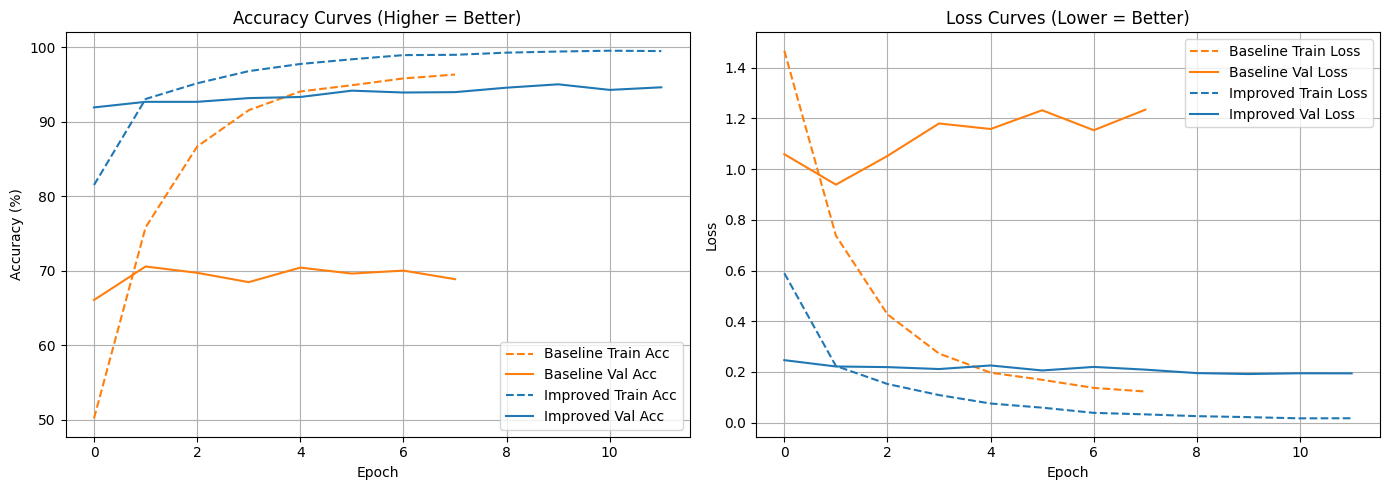

In [3]:
#improving the fine-tuning results with some methods one by one
import copy
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import datasets, transforms, models
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# 1. PREPROCESSING & DATA AUGMENTATION

# Baseline: raw 32x32, no augmentation
baseline_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.4914, 0.4822, 0.4465), (0.2023, 0.1994, 0.2010))
])

# Improved: Resizing to 96x96 (preserves spatial features), Data Augmentation, ImageNet stats
improved_train_transform = transforms.Compose([
    transforms.Resize((96, 96)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomCrop(96, padding=8),
    transforms.ToTensor(),
    transforms.Normalize((0.485, 0.456, 0.406), (0.229, 0.224, 0.225))
])

# Test set gets Resize + Normalize ONLY (we dont augment test data!)
improved_test_transform = transforms.Compose([
    transforms.Resize((96, 96)),
    transforms.ToTensor(),
    transforms.Normalize((0.485, 0.456, 0.406), (0.229, 0.224, 0.225))
])

# Loading CIFAR-10 (using 10,000 train / 2,000 test subset so both run in ~2 mins on Colab)
train_base = torch.utils.data.Subset(datasets.CIFAR10("./data", train=True, download=True, transform=baseline_transform), range(10000))
test_base  = torch.utils.data.Subset(datasets.CIFAR10("./data", train=False, download=True, transform=baseline_transform), range(2000))

train_imp  = torch.utils.data.Subset(datasets.CIFAR10("./data", train=True, download=True, transform=improved_train_transform), range(10000))
test_imp   = torch.utils.data.Subset(datasets.CIFAR10("./data", train=False, download=True, transform=improved_test_transform), range(2000))

loaders_base = (DataLoader(train_base, batch_size=64, shuffle=True), DataLoader(test_base, batch_size=64))
loaders_imp  = (DataLoader(train_imp, batch_size=64, shuffle=True),  DataLoader(test_imp, batch_size=64))


# 2. TRAINING ENGINE WITH EARLY STOPPING & HISTORY TRACKING
def run_experiment(model, loaders, optimizer, scheduler=None, epochs=10, patience=3, name="Model"):
    train_loader, test_loader = loaders
    criterion = nn.CrossEntropyLoss()
    model.to(device)

    history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
    best_val_loss = float("inf")
    best_weights = copy.deepcopy(model.state_dict())
    epochs_no_improve = 0

    for epoch in range(epochs):
        # --- Training Phase ---
        model.train()
        tr_loss, tr_correct, tr_total = 0.0, 0, 0
        for x, y in train_loader:
            x, y = x.to(device), y.to(device)
            optimizer.zero_grad()
            out = model(x)
            loss = criterion(out, y)
            loss.backward()
            optimizer.step()

            tr_loss += loss.item() * x.size(0)
            tr_correct += (out.argmax(1) == y).sum().item()
            tr_total += y.size(0)

        if scheduler:
            scheduler.step()

        # --- Validation / Testing Phase ---
        model.eval()
        val_loss, val_correct, val_total = 0.0, 0, 0
        with torch.no_grad():
            for x, y in test_loader:
                x, y = x.to(device), y.to(device)
                out = model(x)
                loss = criterion(out, y)
                val_loss += loss.item() * x.size(0)
                val_correct += (out.argmax(1) == y).sum().item()
                val_total += y.size(0)

        ep_tr_loss, ep_val_loss = tr_loss / tr_total, val_loss / val_total
        ep_tr_acc, ep_val_acc = 100 * tr_correct / tr_total, 100 * val_correct / val_total

        history["train_loss"].append(ep_tr_loss)
        history["val_loss"].append(ep_val_loss)
        history["train_acc"].append(ep_tr_acc)
        history["val_acc"].append(ep_val_acc)

        print(f"[{name}] Epoch {epoch+1:02d}/{epochs} | Train Acc: {ep_tr_acc:.1f}% | Val Acc: {ep_val_acc:.1f}% | Val Loss: {ep_val_loss:.4f}")

        # --- Early Stopping Check ---
        if ep_val_loss < best_val_loss:
            best_val_loss = ep_val_loss
            best_weights = copy.deepcopy(model.state_dict())
            epochs_no_improve = 0
        else:
            epochs_no_improve += 1
            if epochs_no_improve >= patience:
                print(f"--> Early stopping triggered at epoch {epoch+1}! Restoring best model.")
                break

    model.load_state_dict(best_weights)
    return history


# 3. MODEL A: BASELINE FINE-TUNING (Only last block unfrozen, no dropout/aug)

model_base = models.resnet50(weights="DEFAULT")
for p in model_base.parameters():
    p.requires_grad = False
for p in model_base.layer4.parameters():
    p.requires_grad = True
model_base.fc = nn.Linear(model_base.fc.in_features, 10)

opt_base = optim.Adam(filter(lambda p: p.requires_grad, model_base.parameters()), lr=1e-3)
hist_base = run_experiment(model_base, loaders_base, opt_base, epochs=8, patience=8, name="Baseline")

# 4. MODEL B: IMPROVED FINE-TUNING (More layers, Dropout, LR Scheduler, Early Stop)

model_imp = models.resnet50(weights="DEFAULT")
for p in model_imp.parameters():
    p.requires_grad = False
# Unfreeze MORE layers (layer3 + layer4)
for p in model_imp.layer3.parameters():
    p.requires_grad = True
for p in model_imp.layer4.parameters():
    p.requires_grad = True

# Different classifier layers with BatchNorm + Dropout to prevent overfitting
model_imp.fc = nn.Sequential(
    nn.Linear(model_imp.fc.in_features, 512),
    nn.BatchNorm1d(512),
    nn.ReLU(),
    nn.Dropout(0.5),
    nn.Linear(512, 10)
)

opt_imp = optim.AdamW(filter(lambda p: p.requires_grad, model_imp.parameters()), lr=2e-4, weight_decay=1e-4)
sched_imp = optim.lr_scheduler.CosineAnnealingLR(opt_imp, T_max=12)
hist_imp = run_experiment(model_imp, loaders_imp, opt_imp, scheduler=sched_imp, epochs=12, patience=3, name="Improved")

# 5. PLOTTING PERFORMANCE CURVES SIDE-BY-SIDE

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Accuracy Plot
axes[0].plot(hist_base["train_acc"], "--", label="Baseline Train Acc", color="tab:orange")
axes[0].plot(hist_base["val_acc"], "-", label="Baseline Val Acc", color="tab:orange")
axes[0].plot(hist_imp["train_acc"], "--", label="Improved Train Acc", color="tab:blue")
axes[0].plot(hist_imp["val_acc"], "-", label="Improved Val Acc", color="tab:blue")
axes[0].set_title("Accuracy Curves (Higher = Better)")
axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("Accuracy (%)"); axes[0].legend(); axes[0].grid(True)

# Loss Plot
axes[1].plot(hist_base["train_loss"], "--", label="Baseline Train Loss", color="tab:orange")
axes[1].plot(hist_base["val_loss"], "-", label="Baseline Val Loss", color="tab:orange")
axes[1].plot(hist_imp["train_loss"], "--", label="Improved Train Loss", color="tab:blue")
axes[1].plot(hist_imp["val_loss"], "-", label="Improved Val Loss", color="tab:blue")
axes[1].set_title("Loss Curves (Lower = Better)")
axes[1].set_xlabel("Epoch"); axes[1].set_ylabel("Loss"); axes[1].legend(); axes[1].grid(True)

plt.tight_layout()
plt.show()